In [76]:
import pandas as pd 
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [34]:
df_train = pd.read_csv("H&M/training set.csv")
df_test = pd.read_csv("H&M/test set.csv")

In [35]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Height  3000 non-null   float64
 1   Weight  3000 non-null   float64
 2   Sex     3000 non-null   object 
dtypes: float64(2), object(1)
memory usage: 70.4+ KB


In [36]:
df_train.head()

,Height,Weight,Sex
0,165.65,35.41,Female
1,148.53,74.45,Female
2,167.04,81.22,Male
3,161.54,71.47,Male
4,174.31,78.18,Male


In [37]:
df_test.head()

,Height,Weight,Sex
0,146.323241,59.861065,Female
1,175.695412,77.863687,Male
2,183.216164,72.131992,Male
3,184.245269,77.546000,Male
4,132.302261,55.188496,Female


In [38]:
#i want to get the test dataset to be rounded to two decimal places so that it would not cause any conflict
df_test['Height'] = round(df_test['Height'], 2)
df_test['Weight'] = round(df_test['Weight'], 2)

In [39]:
df_test.head()

,Height,Weight,Sex
0,146.32,59.86,Female
1,175.70,77.86,Male
2,183.22,72.13,Male
3,184.25,77.55,Male
4,132.30,55.19,Female


<function matplotlib.pyplot.show(close=None, block=None)>

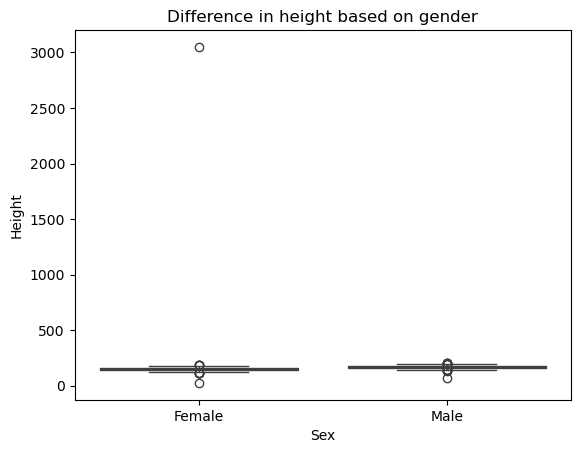

In [40]:
sns.boxplot(x='Sex', y='Height', data=df_train)
plt.title("Difference in height based on gender")
plt.ylabel('Height')
plt.show

In [41]:
#i am trying to find out why i am getting the plot like this maybe it is an outlier issue 

In [42]:
df_train['Height'].describe()

count    3000.000000
mean      161.350427
std        54.912719
min        25.680000
25%       149.502500
50%       160.870000
75%       171.632500
max      3050.000000
Name: Height, dtype: float64

In [43]:
#as you can see there is an outlier of 3050 and that is what have been messing up my plot,
# so i am goung to set a threshold

In [44]:
df_train = df_train[(df_train['Height'] < 250)]
df_train['Height'].describe()

count    2999.000000
mean      160.387222
std        15.238003
min        25.680000
25%       149.495000
50%       160.860000
75%       171.625000
max       202.670000
Name: Height, dtype: float64

In [45]:
# as you can see after setting a threshold of 250
# our max height is now 199
# so let us plot again

<function matplotlib.pyplot.show(close=None, block=None)>

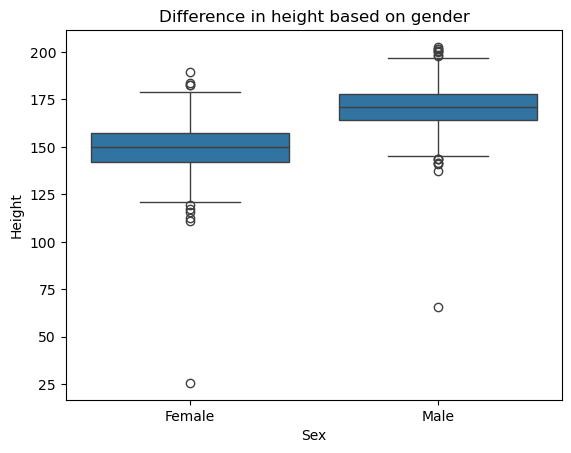

In [46]:
sns.boxplot(x='Sex', y='Height', data=df_train)
plt.title("Difference in height based on gender")
plt.ylabel('Height')
plt.show

In [47]:
# seems like i have to remove overly low values eoo brcause that is also affecting my plot 
df_train = df_train[(df_train['Height'] >= 100)]

<function matplotlib.pyplot.show(close=None, block=None)>

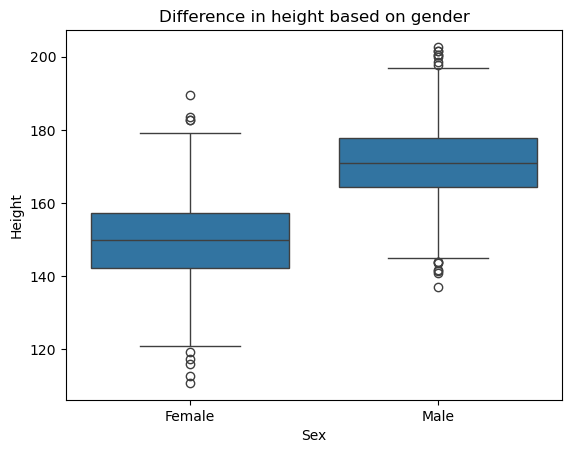

In [48]:
sns.boxplot(x='Sex', y='Height', data=df_train)
plt.title("Difference in height based on gender")
plt.ylabel('Height')
plt.show

In [49]:
# from this plot we can see that the male median height is around 170
# while the female median height is around 150 

# the middle 50% of male (that is the box) is a step higher than that of the females
# we can also see that the tallest females are taller than the average males 
# and finally we can see from this plot that both male and female have outliers

## let us do the same for weight 


In [50]:
df_train['Weight'].describe()
# now we can see that we also have some outliers here
# we have a minimum value of 8 and a max 485, that is not normal
# i am not fat phobic, those large numbers could make my model misbehave

count    2997.000000
mean       68.412686
std        17.040756
min         8.530000
25%        57.940000
50%        67.380000
75%        77.990000
max       485.000000
Name: Weight, dtype: float64

In [55]:
pd.set_option('display.max_rows', None)
df_train['Weight']
# here i went through the data to know what a realistic threshold would be

0        35.41
1        74.45
2        81.22
3        71.47
4        78.18
5        79.27
6        63.71
7        86.01
8        88.33
9        87.36
10       78.58
11       88.08
12       56.30
13       53.46
14       60.95
15       72.51
16       86.80
17       54.12
18       73.36
19       69.20
20       56.01
21      107.25
22       92.24
23       64.44
24       68.75
25       58.43
26       59.52
27       62.65
28       44.07
29       83.36
30       66.12
31       91.02
32       80.20
33       63.68
34       62.75
35       50.04
36       60.49
37       74.57
38       54.64
39       84.34
40       75.18
41       78.39
42       84.76
43       83.54
44       63.06
45       52.13
46       65.25
47       73.67
48       52.42
49       54.45
50       63.91
51       68.34
52       77.50
53       87.80
54       73.04
55       61.40
56       52.81
57       94.37
58      110.01
59       82.74
60       70.33
61       43.02
62       54.87
63       57.93
64       73.70
65       43.37
66       9

In [52]:
df_train = df_train[(df_train['Weight'] >= 25) & (df_train['Weight'] <= 200)]
df_train['Weight'].describe()

count    2992.000000
mean       68.338295
std        15.153882
min        25.500000
25%        57.965000
50%        67.400000
75%        77.992500
max       121.980000
Name: Weight, dtype: float64

In [53]:
# i made the minimum weight 25 and the maximum weight 200

<function matplotlib.pyplot.show(close=None, block=None)>

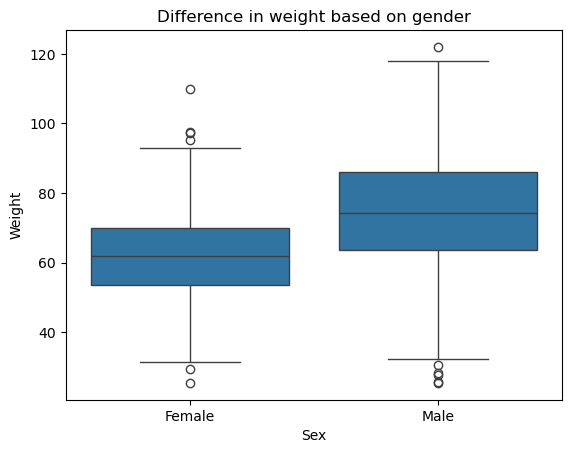

In [54]:
sns.boxplot(x='Sex', y='Weight', data=df_train)
plt.title("Difference in weight based on gender")
plt.ylabel('Weight')
plt.show

In [ ]:
# from this we can see that the male weight is slightly higher than the females 
# and the spread on the male 50 percentile inter quartile range is larger


## let us move to modelling of the data

In [ ]:
# for our model of choice i am going with K neighbour classifier

In [ ]:
# i have to split the data into features and target variable 

In [58]:
X_train = df_train.drop(columns=['Sex'])  
y_train = df_train['Sex']  

In [59]:
# now we would fit the model or train the model
knn = KNeighborsClassifier()
knn.fit(X_train, y_train)

KNeighborsClassifier()

In [ ]:
# lwt me quickly take a look at the tesst data 

In [60]:
df_test.describe()

,Height,Weight
count,205.000000,205.000000
mean,160.873902,69.927122
std,15.170859,15.462420
min,123.010000,34.730000
25%,148.940000,58.580000
50%,161.750000,69.540000
75%,172.610000,77.960000
max,199.280000,129.410000


In [ ]:
# it looks fine to me so i am going to test our model with it

In [61]:
# let me split the test data too and then score 
X_test = df_test.drop(columns=['Sex'])
y_test = df_test['Sex']

In [62]:
knn.score(X_test, y_test)

0.8536585365853658

In [ ]:
# we got an 85.3 percent accuracy but i feel like i can do better 

In [70]:
model_0 = RandomForestClassifier()
model_0.fit(X_train, y_train)

RandomForestClassifier()

In [71]:
model_0.score(X_test, y_test)

0.8731707317073171

In [ ]:
# i would do a cconfusion_matrix to better understand my model performance
# firstly let us get our predicted value 

In [74]:
y_pred = model_0.predict(X_test)

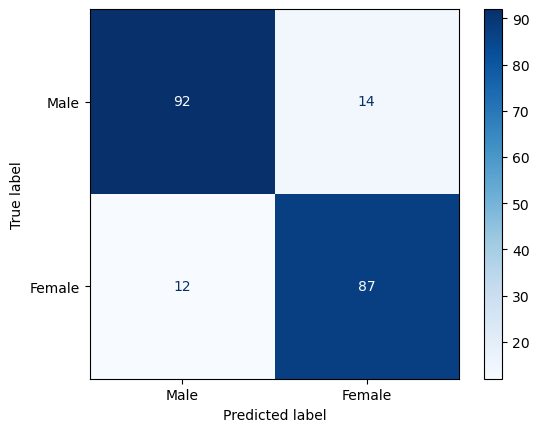

In [78]:
labels = ['Male', 'Female']
cm = confusion_matrix(y_test, y_pred, labels=labels)

# Display the visual plot
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(cmap=plt.cm.Blues)

plt.show()

In [ ]:
# from this cconfusion_matrix we can see that out of 205 samples
# our model correctly predicted 92 males and 87 females
# there is room for improvement and we would get back to that 
# let me quickly whip up a program that allow's us give the model direct input

In [83]:
def predict_gender(model_0):
    try:
        height = float(input("Enter height: "))
        weight = float(input("Enter weight: "))
    except ValueError:
        return "Invalid input. Please enter numbers."

    user_data = pd.DataFrame([[height, weight]], columns=["Height", "Weight"])
    prediction = model_0.predict(user_data)[0]
    
    return "Female" if prediction == 1 else "Male"

In [84]:
predict_gender(model_0)

Enter height:  180
Enter weight:  55


'Male'